**Анализ Данных: УУНиТ, Забигуллин Камиль, Топ-201Б. Простейший мессенджер на фласке.**

---

Csv файлы есть в репозитории гитхаба: https://github.com/zx345opa228-jpg/Python-project-UUNIT/tree/main/gen


*Графики построены при помощи pandas и matplotlib*



**Графики**

1. Уведомления в группах

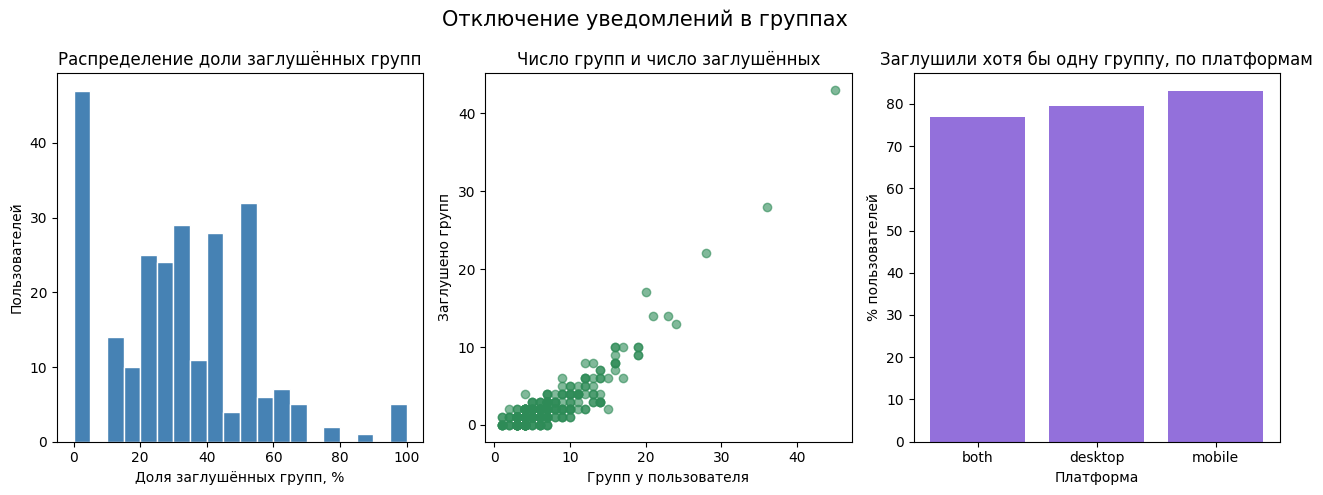

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("group_notifications_muting.csv")

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
fig.suptitle("Отключение уведомлений в группах", fontsize=15)

#Распределение доли заглушённых групп
axes[0].hist(df["muted_share_pct"], bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("Распределение доли заглушённых групп")
axes[0].set_xlabel("Доля заглушённых групп, %")
axes[0].set_ylabel("Пользователей")

#Число групп и число заглушённых
axes[1].scatter(df["groups_count"], df["muted_groups"], alpha=0.6, color="seagreen")
axes[1].set_title("Число групп и число заглушённых")
axes[1].set_xlabel("Групп у пользователя")
axes[1].set_ylabel("Заглушено групп")

#Доля заглушивших хоть одну группу по платформам
by_pl = df.groupby("platform")["muted_any"].mean() * 100
axes[2].bar(by_pl.index, by_pl.values, color="mediumpurple")
axes[2].set_title("Заглушили хотя бы одну группу, по платформам")
axes[2].set_xlabel("Платформа")
axes[2].set_ylabel("% пользователей")

plt.tight_layout()
plt.show()


2. Нагрузка на сервер

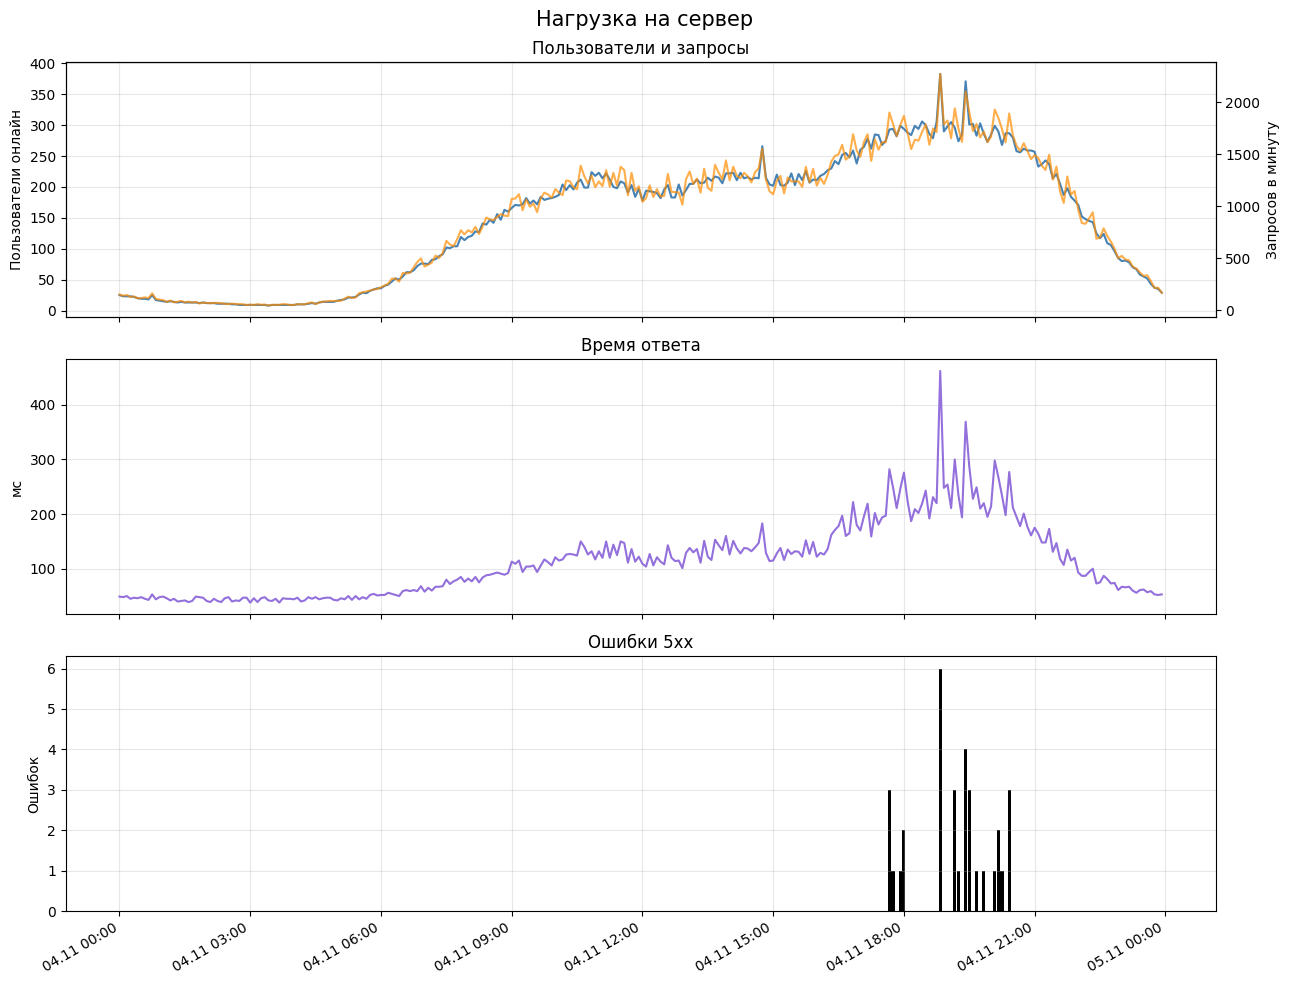

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df = pd.read_csv("server_load.csv", parse_dates=["timestamp"])

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
fig.suptitle("Нагрузка на сервер", fontsize=15)

axes[0].plot(df["timestamp"], df["online_users"], color="steelblue")
axes[0].set_ylabel("Пользователи онлайн")
ax0b = axes[0].twinx()
ax0b.plot(df["timestamp"], df["requests_per_min"], color="darkorange", alpha=0.7)
ax0b.set_ylabel("Запросов в минуту")
axes[0].set_title("Пользователи и запросы")

axes[1].plot(df["timestamp"], df["response_ms"], color="mediumpurple")
axes[1].set_ylabel("мс")
axes[1].set_title("Время ответа")

axes[2].bar(df["timestamp"], df["errors_5xx"], width=0.003, color="black")
axes[2].set_ylabel("Ошибок")
axes[2].set_title("Ошибки 5xx")
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M"))

for ax in axes:
    ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


3. Доля спама/хама

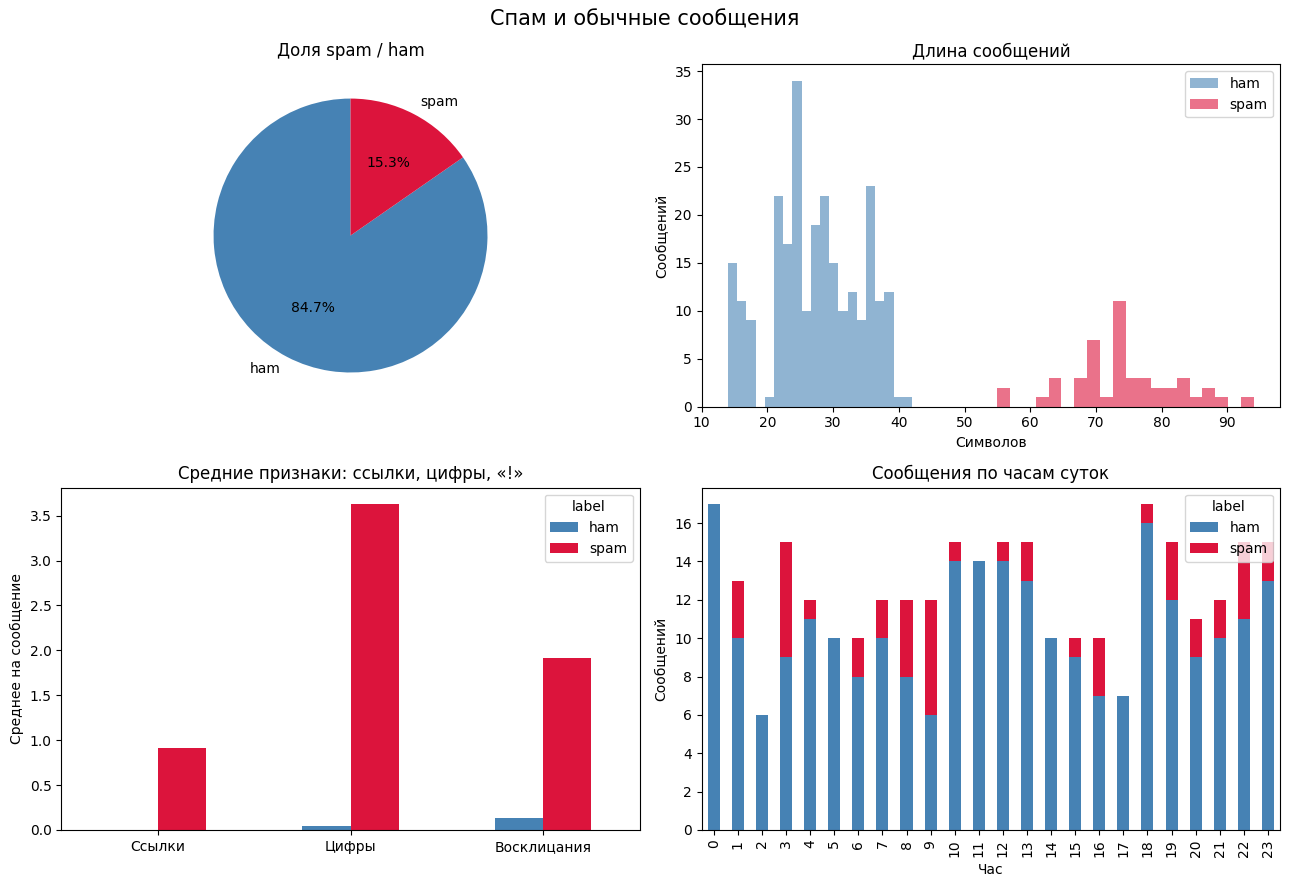

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("spam_ham_messages.csv", parse_dates=["timestamp"])
df["hour"] = df["timestamp"].dt.hour

colors = {"ham": "steelblue", "spam": "crimson"}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("Спам и обычные сообщения", fontsize=15)

#Соотношение
counts = df["label"].value_counts()
axes[0, 0].pie(counts.values, labels=counts.index, autopct="%1.1f%%",
               colors=[colors[l] for l in counts.index], startangle=90)
axes[0, 0].set_title("Доля spam / ham")

#Длина текста
for label, g in df.groupby("label"):
    axes[0, 1].hist(g["text_length"], bins=20, alpha=0.6, label=label, color=colors[label])
axes[0, 1].set_title("Длина сообщений")
axes[0, 1].set_xlabel("Символов")
axes[0, 1].set_ylabel("Сообщений")
axes[0, 1].legend()

#Средние признаки
feats = ["links_count", "digits_count", "exclamation_count"]
means = df.groupby("label")[feats].mean().T
means.plot(kind="bar", ax=axes[1, 0], color=[colors[c] for c in means.columns])
axes[1, 0].set_title("Средние признаки: ссылки, цифры, «!»")
axes[1, 0].set_xticklabels(["Ссылки", "Цифры", "Восклицания"], rotation=0)
axes[1, 0].set_ylabel("Среднее на сообщение")

#Сообщения по часам
by_hour = df.groupby(["hour", "label"]).size().unstack(fill_value=0)
by_hour.plot(kind="bar", stacked=True, ax=axes[1, 1], color=[colors[c] for c in by_hour.columns])
axes[1, 1].set_title("Сообщения по часам суток")
axes[1, 1].set_xlabel("Час")
axes[1, 1].set_ylabel("Сообщений")

plt.tight_layout()
plt.show()

4. Доли устройств Mobile/Desktop/Tablet

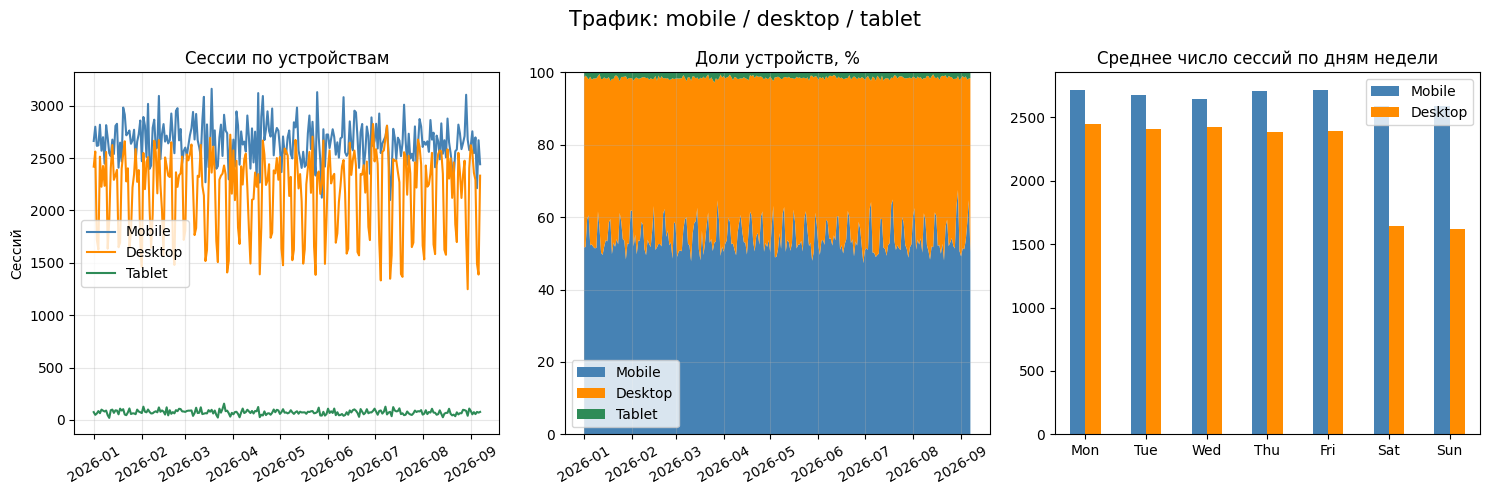

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("traffic_mobile_desktop.csv", parse_dates=["date"])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Трафик: mobile / desktop / tablet", fontsize=15)

#Сессии по устройствам во времени
axes[0].plot(df["date"], df["mobile_sessions"], label="Mobile", color="steelblue")
axes[0].plot(df["date"], df["desktop_sessions"], label="Desktop", color="darkorange")
axes[0].plot(df["date"], df["tablet_sessions"], label="Tablet", color="seagreen")
axes[0].set_title("Сессии по устройствам")
axes[0].set_ylabel("Сессий")
axes[0].legend()

#Доли устройств
axes[1].stackplot(df["date"], df["mobile_pct"], df["desktop_pct"], df["tablet_pct"],
                  labels=["Mobile", "Desktop", "Tablet"],
                  colors=["steelblue", "darkorange", "seagreen"])
axes[1].set_title("Доли устройств, %")
axes[1].set_ylim(0, 100)
axes[1].legend(loc="lower left")

#Средние сессии по дням недели
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wd = df.groupby("weekday")[["mobile_sessions", "desktop_sessions"]].mean().reindex(order)
wd.plot(kind="bar", ax=axes[2], color=["steelblue", "darkorange"])
axes[2].set_title("Среднее число сессий по дням недели")
axes[2].set_xlabel("")
axes[2].set_xticklabels(order, rotation=0)
axes[2].legend(["Mobile", "Desktop"])

for ax in axes[:2]:
    ax.tick_params(axis="x", rotation=30)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Анализ данных по графикам**

1. **Отключение уведомлений в группах**

**`Распределение доли заглушённых групп`** В среднем заглушено 30,7% групп. 18,8% пользователей не заглушили ни одной группы, и только 1,6% заглушили все. Мьют работает как точечный фильтр, а не как уход из общения.

**`Число групп и число заглушённых`** Корреляция 0,89: у тех, кто в 3 группах и меньше, заглушено около 23% групп, а у тех, кто в 10 и больше, 44%. Чем больше групп, тем больше шума, поэтому нужны гибкие настройки уведомлений (мьют на время, только упоминания).

**`Заглушили хотя бы одну группу, по платформам`** Mobile 83%, desktop 79,5%, обе платформы 77%. Разница небольшая и при такой выборке не показательна, а функция мьюта нужна около 81% пользователей.

2. **Нагрузка на сервер**

**`Пользователи и запросы`** Кривые почти совпадают (корреляция 0,99), примерно 6 запросов в минуту на пользователя. Ночью минимум (8 онлайн в 03:25), вечерний пик в 17–20 часов (максимум 383 онлайн и 2271 запрос в минуту в 18:50).

**`Время ответа`** Ночью около 45 мс, днём 105–140 мс, вечером 210–245 мс, максимум 462 мс. Оно растёт быстрее, чем число пользователей, значит, на пике сервер близок к пределу.

**`Ошибки 5xx`** Все 33 ошибки случились с 17:40 до 20:25, когда онлайн было около 270 человек и больше. Это примерный порог устойчивости, и оптимизировать стоит именно вечерний пик.

3. **Спам и обычные сообщения**

**`Доля spam / ham ` ** 84,7% обычных сообщений и 15,3% спама.

**`Длина сообщений`** Обычные 14–42 символа (в среднем 27), спам 55–94 (в среднем 74). Диапазоны не пересекаются, так что длина разделяет классы почти идеально.

**`Средние признаки`** ссылки, цифры, «!». У спама в среднем 0,91 ссылки, 3,6 цифры и 1,9 знака «!», у обычных сообщений почти 0, 0,04 и 0,14. Базовый фильтр можно собрать из правил: ссылка, цифры, «!» и длина выше порога.

**`Сообщения по часам суток`** Обычные сообщения имеют пики около полуночи и в 18 часов, а спам распределён равномерно (ночью 13,7%, днём 15,9%). Время суток для фильтрации не подходит.

4. **Трафик mobile / desktop / tablet **

**`Сессии по устройствам`** В среднем в день 2663 mobile, 2186 desktop и 74 tablet, а mobile опережает desktop в 93,6% дней. Тренда нет, трафик стабильно держится на 4800–5000 сессий в день, поэтому нужен mobile-first, а планшеты отдельно оптимизировать не обязательно, они вменьшинстве)

**`Доли устройств`** Mobile 54,4%, desktop 44,1%, tablet 1,5%, и соотношение не меняется со временем. Десктопная версия всё равно нужна, ведь за компьютером почти половина пользователей.

**`Среднее число сессий по дням недели`** По выходным трафик на 17% ниже (около 4290 против 5180 по будням). Падает именно desktop (примерно с 2400 до 1600), а mobile почти не меняется. Доля mobile в выходные вырастает с 52% до 60%.

**Выводы**

*Данные синтетические и охватывают небольшую выборку. Но даже если судить по синтетическим графикам то:*

**Приоритет интерфейса:** Mobile даёт 54% трафика и опережает desktop почти во все дни, причём по выходным его доля растёт до 60%. Поэтому нужен адаптивный интерфейс, который удобно использовать на телефоне, а десктопная версия остаётся полноценной, но второстепенной. Отдельная версия под планшет не нужна: на него приходится всего 1,5% сессий.

**Управление уведомлениями.** 81% пользователей заглушают хотя бы одну группу, а чем больше у человека групп, тем выше доля заглушённых. В MVP стоит заложить мьют для групп, а затем добавить режимы «только упоминания» и мьют на время.

**Защита от спама.** Спам составляет около 15% сообщений и хорошо отличается по простым признакам: длина, ссылки, цифры и «!». Для MVP хватит фильтра Flask, без ML. Время суток как признак использовать не стоит. Можно что-то по типу простого байесовского классификатора реализовать

**Нагрузка и масштабирование.** Сервер упирается в вечерний пик: ошибки 5xx начинаются примерно при 270 одновременных пользователях и около 1700 запросов в минуту. Для MVP достаточно тестировать систему на таких значениях.

**Мониторинг.** Главные метрики для отслеживания: число пользователей онлайн, запросов в минуту, время ответа и число ошибок 5xx. Их рост связан между собой, поэтому достаточно одного дашборда по этим четырём показателям.
